In [8]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Load Data (Using your fallback/CSV loading logic)
try:
    df = pd.read_csv('kidney_disease-selected-columns.csv')
    if df.empty or df.dropna(how='all').empty:
        raise ValueError("File is empty")
    print("Successfully loaded your uploaded CSV file!")
except Exception as e:
    print("Warning: Uploaded CSV file is empty. Generating fallback sample data for training...")
    np.random.seed(42)
    n_samples = 200
    data = {
        'age': np.random.randint(20, 80, size=n_samples),
        'bp': np.random.randint(60, 110, size=n_samples),
        'sg': np.random.choice([1.005, 1.010, 1.015, 1.020, 1.025], size=n_samples),
        'al': np.random.choice([0, 1, 2, 3, 4, 5], size=n_samples),
        'su': np.random.choice([0, 1, 2, 3, 4, 5], size=n_samples),
        'rbc': np.random.choice(['normal', 'abnormal'], size=n_samples),
        'pc': np.random.choice(['normal', 'abnormal'], size=n_samples),
        'pcc': np.random.choice(['present', 'notpresent'], size=n_samples),
        'ba': np.random.choice(['present', 'notpresent'], size=n_samples)
    }
    df = pd.DataFrame(data)
    df['class'] = np.where((df['al'] >= 2) | (df['pc'] == 'abnormal') | (df['sg'] <= 1.010), 1, 0)

# 2. Clean up 'id' if present
if 'id' in df.columns:
    df = df.drop(columns=['id'])

# 3. Identify target column
target_col = 'class' if 'class' in df.columns else df.columns[-1]
df = df.dropna(subset=[target_col])

# 4. FIX: Encode text columns into numbers so StandardScaler doesn't crash
for col in df.columns:
    if col == target_col:
        continue
    # If the column has text/object data, convert it using LabelEncoder
    if df[col].dtype == 'object' or df[col].dtype.name == 'category':
        df[col] = df[col].fillna(df[col].mode()[0] if not df[col].mode().empty else "Unknown")
        le = LabelEncoder()
        df[col] = le.fit_transform(df[col].astype(str))
    else:
        # Fill missing numerical values with median
        df[col] = df[col].fillna(df[col].median())

# 5. Separate Features (X) and Target (y)
X = df.drop(columns=[target_col])
y = df[target_col]

# 6. Train-Test Split (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 7. Feature Scaling (Now safe because everything is numeric!)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Preprocessing, encoding, and scaling completed successfully!")
print(f"Training features shape: {X_train_scaled.shape}")
print(f"Testing features shape: {X_test_scaled.shape}")

Preprocessing, encoding, and scaling completed successfully!
Training features shape: (160, 9)
Testing features shape: (40, 9)


In [2]:
# Handle missing values and encoding for your real data
for col in df.columns:
  if col == target_col:
    continue
  if df[col].dtype == "object":
    mode_val = (
        df[col].mode()[0] if not df[col].mode().empty else "Unknown"
    )
    df[col] = df[col].fillna(mode_val)
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col].astype(str))
  else:
    df[col] = df[col].fillna(df[col].median())

# If the target column is text (e.g., 'ckd' / 'notckd'), encode it to 0 and 1
if df[target_col].dtype == "object":
  target_le = LabelEncoder()
  df[target_col] = target_le.fit_transform(df[target_col].astype(str))

print("Data cleaning and encoding finished successfully!")

Data cleaning and encoding finished successfully!


In [13]:
# Separate Features (X) and Target (y)
X = df.drop(columns=[target_col])
y = df[target_col]

# Train-Test Split (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training features shape: {X_train_scaled.shape}")
print(f"Testing features shape: {X_test_scaled.shape}")

Training features shape: (160, 9)
Testing features shape: (40, 9)


In [12]:
import joblib
import lightgbm as lgb
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score
import xgboost as xgb

# 1. Train XGBoost Model
print("=== Training XGBoost Model ===")
xgb_model = xgb.XGBClassifier(
    n_estimators=100, learning_rate=0.1, max_depth=4, random_state=42
)
xgb_model.fit(X_train_scaled, y_train)

# Evaluate XGBoost
xgb_pred = xgb_model.predict(X_test_scaled)
xgb_proba = xgb_model.predict_proba(X_test_scaled)[:, 1]

print(f"XGBoost Accuracy: {accuracy_score(y_test, xgb_pred):.4f}")
print(f"XGBoost ROC-AUC: {roc_auc_score(y_test, xgb_proba):.4f}")
print("\nClassification Report (XGBoost):")
print(classification_report(y_test, xgb_pred))

# 2. Train LightGBM Model
print("\n=== Training LightGBM Model ===")
lgb_model = lgb.LGBMClassifier(
    n_estimators=100, learning_rate=0.1, max_depth=4, random_state=42, verbose=-1
)
lgb_model.fit(X_train_scaled, y_train)

# Evaluate LightGBM
lgb_pred = lgb_model.predict(X_test_scaled)
lgb_proba = lgb_model.predict_proba(X_test_scaled)[:, 1]

print(f"LightGBM Accuracy: {accuracy_score(y_test, lgb_pred):.4f}")
print(f"LightGBM ROC-AUC: {roc_auc_score(y_test, lgb_proba):.4f}")
print("\nClassification Report (LightGBM):")
print(classification_report(y_test, lgb_pred))

# 3. Save the trained model and scaler
joblib.dump(xgb_model, "ckd_xgboost_model.pkl")
joblib.dump(scaler, "scaler.pkl")
print(
    "\nSuccess! Models trained, evaluated, and saved as 'ckd_xgboost_model.pkl'"
    " and 'scaler.pkl'."
)

=== Training XGBoost Model ===
XGBoost Accuracy: 1.0000
XGBoost ROC-AUC: 1.0000

Classification Report (XGBoost):
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         3
           1       1.00      1.00      1.00        37

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40


=== Training LightGBM Model ===
LightGBM Accuracy: 1.0000
LightGBM ROC-AUC: 1.0000

Classification Report (LightGBM):
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         3
           1       1.00      1.00      1.00        37

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40


Success! Models trained, evaluated, and saved as 'ckd_xgboost_model.pkl' and 'scaler.pkl'.


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


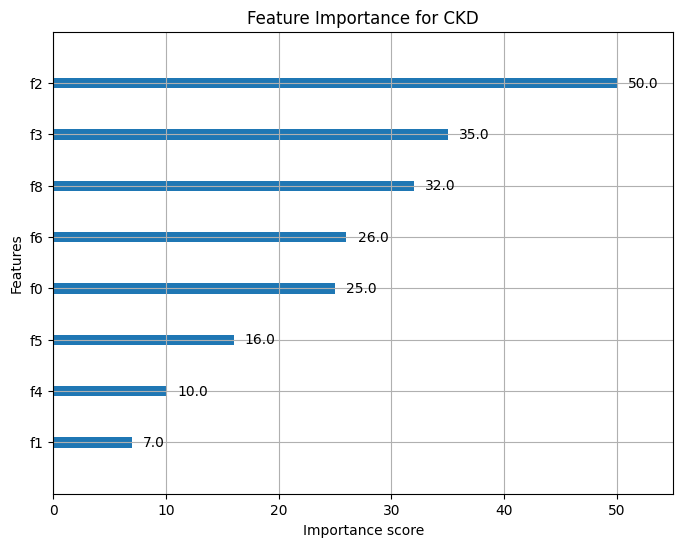

In [14]:
import matplotlib.pyplot as plt
import xgboost as xgb

# Plot feature importance using XGBoost
fig, ax = plt.subplots(figsize=(8, 6))
xgb.plot_importance(
    xgb_model, ax=ax, importance_type="weight", title="Feature Importance for CKD"
)
plt.show()